In [11]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.append(Path.cwd())
Path.cwd()

WindowsPath('c:/dev/predictive-maintenance-mlops')

In [12]:
import optuna
from turbofan.features import get_feature_columns
from turbofan.train import build_training_data, load_params, validation_rmse

In [14]:
features = get_feature_columns()
params = load_params()
train = build_training_data(params)

In [16]:
for depth in [6, 12, 18]:
    settings = {
        "n_estimators": 100,
        "max_depth": depth,
        "min_samples_leaf": 1,
        "random_state": 42
    }
    print(depth, round(validation_rmse(train, features, settings), 2))

6 16.57
12 16.61
18 16.77


In [17]:
def objective(trial):
    settings = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 300, step=50),
        "max_depth": trial.suggest_int("max_depth", 4, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "random_state": 42,
    }
    return validation_rmse(train, features, settings)

In [18]:
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
study.optimize(objective, n_trials=20)

[I 2026-10-26 18:37:16,996] A new study created in memory with name: no-name-bb5df6ba-05c6-4a70-8e6b-e92cf3e28d95
[I 2026-10-26 18:37:26,158] Trial 0 finished with value: 16.561701840076648 and parameters: {'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 8}. Best is trial 0 with value: 16.561701840076648.
[I 2026-10-26 18:37:32,169] Trial 1 finished with value: 16.55546519789564 and parameters: {'n_estimators': 200, 'max_depth': 6, 'min_samples_leaf': 2}. Best is trial 1 with value: 16.55546519789564.
[I 2026-10-26 18:37:35,564] Trial 2 finished with value: 16.683803816602534 and parameters: {'n_estimators': 50, 'max_depth': 18, 'min_samples_leaf': 7}. Best is trial 1 with value: 16.55546519789564.
[I 2026-10-26 18:37:40,086] Trial 3 finished with value: 17.47007669580289 and parameters: {'n_estimators': 250, 'max_depth': 4, 'min_samples_leaf': 10}. Best is trial 1 with value: 16.55546519789564.
[I 2026-10-26 18:37:47,938] Trial 4 finished with value: 16.487066581754462 and p

In [20]:
print("best value rmse:", round(study.best_value, 2))
print("best_settings:", study.best_params)

best value rmse: 16.44
best_settings: {'n_estimators': 200, 'max_depth': 9, 'min_samples_leaf': 7}


In [22]:
df = study.trials_dataframe()
df.sort_values("value")[["number", "value", "params_n_estimators", "params_max_depth", "params_min_samples_leaf"]].head(10)

,number,value,params_n_estimators,params_max_depth,params_min_samples_leaf
12,12,16.436581,200,9,7
14,14,16.452161,150,9,10
6,6,16.453250,150,8,7
11,11,16.453250,150,8,7
5,5,16.464316,100,9,6
7,7,16.479415,50,8,4
4,4,16.487067,250,7,2
17,17,16.507082,200,12,8
18,18,16.515164,50,10,9
13,13,16.515565,250,12,7


C:\Users\12368\AppData\Local\Temp\ipykernel_33356\1455980257.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

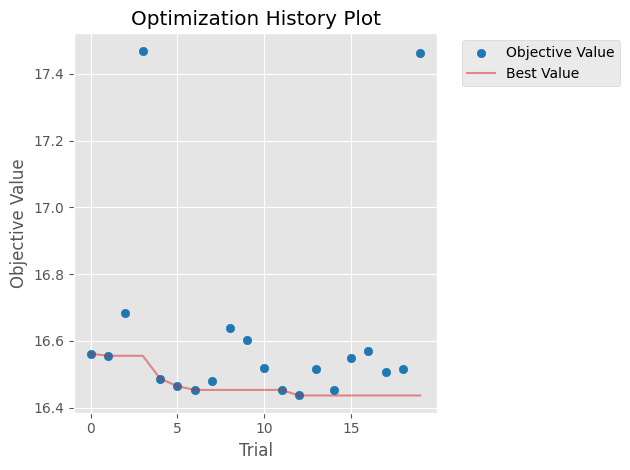

In [24]:
optuna.visualization.matplotlib.plot_optimization_history(study)

C:\Users\12368\AppData\Local\Temp\ipykernel_33356\1036994904.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

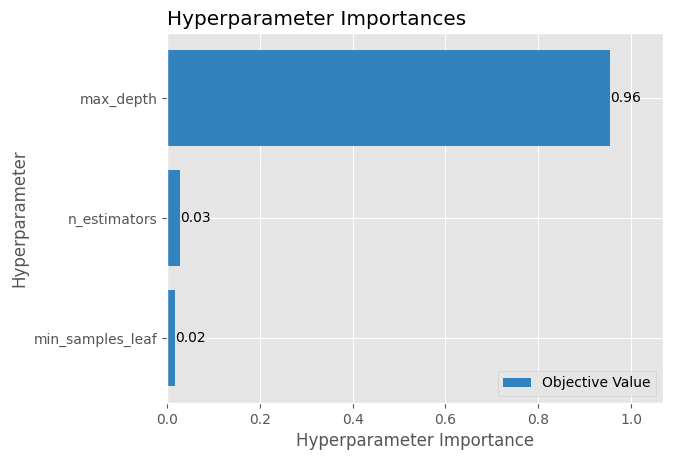

In [25]:
optuna.visualization.matplotlib.plot_param_importances(study)